# ¿Es la muestra apta para validar? Pruebas de fuga y calidad de datos


**Pregunta:** ¿Puede un validador confiar en una cifra de desempeño calculada sobre esta muestra, o una variable lleva la marca de incumplimiento antes de probar el modelo?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** ayuda el notebook 04 del tema 01 (la batería y las luces), no hace falta otro tema
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- explicar por qué un validador revisa la muestra antes de cualquier prueba del modelo, y qué hace una fuga con una cifra de desempeño;
- correr las cuatro pruebas de fuga del motor (orden temporal, el AUC de una sola variable, el traslape de entidades y el AUC de semejanza) y leer cada una contra su regla o su punto de corte;
- contar las cinco revisiones de calidad de datos (completitud, validez, unicidad, consistencia y oportunidad) y convertirlas en una luz;
- leer la variante de fuga versionada del caso C20, donde se plantó una variable que filtra el resultado en un modelo real y la prueba la atrapó, y decir qué no demuestra la prueba.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import dataquality as dq
from riskvalidation.ml import leakage, plants
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo"}
SCREEN = {"temporal": "temporal", "single": "una variable", "overlap": "traslape", "resemblance": "semejanza"}
CHECK_NAMES = ["completitud", "validez", "unicidad", "consistencia", "oportunidad"]

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos fuentes, ambas pequeñas y ambas con respuesta conocida.

- **Los generadores de defectos plantados del motor** (`riskvalidation.ml.plants`): una cartera logística de deudores con tres variables honestas y, si se quiere, una cuarta columna que filtra la marca de incumplimiento. Son sintéticos, se generan desde una semilla y la verdad se conoce exacta, así que una prueba se puede contrastar con ella. No hay datos de terceros ni clase de licencia.
- **La variante de fuga versionada del caso C20** (`data/derived/C20/leakage-planted.json`; propietario: este repositorio). Valida un modelo LightGBM sobre los datos de tarjetas de crédito de Taiwán (UCI, CC BY 4.0, clase mirror-allowed) en que la cadena de cálculo plantó una variable `future_status_code` que contiene la marca de incumplimiento más un poco de ruido, fechada después de la fecha de observación. Se horneó con la versión del motor que imprime la celda siguiente, y este notebook nunca reajusta ese modelo: lee las filas que escribió la cadena de cálculo.

La primera celda abre la variante versionada e imprime lo que dice.

In [2]:
# Abrir la variante versionada: el motor que la horneó, la variable plantada y los valores de la prueba
path = ROOT / "data" / "derived" / "C20" / "leakage-planted.json"
variant = json.loads(path.read_text(encoding="utf-8"))
out = variant["outputs"]
screen = out["screen"]
perf = out["performance"]
print("horneado con riskvalidation", variant["provenance"]["riskvalidation_version"])
print("variable plantada:", out["planted_feature"], "| atrapada:", "sí" if out["caught"] else "no")
print("valores de variables fechados después de la observación:", screen["temporal_order"]["violations"])
largest = screen["single_feature_auc"]
print(
    "mayor AUC de una variable:",
    round(largest["max_auc"], 4),
    "| sospechosa:",
    "sí" if largest["suspect"] else "no",
)
print("proporción de traslape de entidades:", screen["entity_overlap"]["share"])
print("AUC de semejanza:", round(screen["resemblance_auc"], 4))
print(
    "AUC en la muestra de desarrollo:",
    round(perf["development_auc"], 4),
    "| AUC al momento de decidir:",
    round(perf["decision_time_auc"], 4),
)

horneado con riskvalidation 1.0.1
variable plantada: future_status_code | atrapada: sí
valores de variables fechados después de la observación: 9000
mayor AUC de una variable: 0.9998 | sospechosa: sí
proporción de traslape de entidades: 0.0
AUC de semejanza: 0.4932
AUC en la muestra de desarrollo: 0.9997 | AUC al momento de decidir: 0.5028


## Método

Una prueba de validación vale lo que vale la muestra que lee. Si una variable lleva la respuesta, toda cifra de desempeño posterior es halagadora y no dice nada del modelo en uso. Las pruebas del motor son **convenciones, no umbrales regulatorios**: ningún texto supervisor las prescribe (el dossier de investigación sobre riesgo de modelo así lo marca); son las revisiones que corre un validador porque son baratas y atrapan las fallas comunes. Sus puntos de corte son parámetros con nombre de la política.

### Paso 1: orden temporal

Una variable debe conocerse en la fecha de observación. La prueba cuenta los valores de variables fechados **después** de la fecha de observación de su fila; una fecha faltante no es una violación y una fecha igual a la de observación tampoco. La regla no tiene punto de corte: una sola violación es una fuga. La celda siguiente construye tres filas a mano, dos de cuyas fechas de variables caen después de su observación, y cuenta.

In [3]:
# Tres filas a mano: dos fechas de variables caen después de su fecha de observación
observation = np.array(["2024-01-31", "2024-02-29", "2024-03-31"], dtype="datetime64[D]")
feature_dates = np.array(
    [["2024-01-15", "2024-02-01"], ["2024-03-05", "2024-02-20"], ["2024-03-31", "2024-03-30"]],
    dtype="datetime64[D]",
)
print("violaciones:", leakage.temporal_order_violations(feature_dates, observation))
# Una fecha faltante no es una violación, y una fecha igual a la de observación tampoco
with_gaps = feature_dates.copy()
with_gaps[1, 0] = np.datetime64("NaT")
print("violaciones con la fecha tardía faltante:", leakage.temporal_order_violations(with_gaps, observation))

violaciones: 2
violaciones con la fecha tardía faltante: 1


### Paso 2: el AUC de una sola variable

Una variable que ordena a los incumplidores casi perfectamente **por sí sola** es sospechosa de fuga: la información crediticia real rara vez es tan fuerte. Para cada columna $j$ el motor calcula el AUC de la columna contra la marca de incumplimiento (el `disc_auc` del propio motor) y guarda la distancia al azar:

$$A_j = \max\bigl(\mathrm{AUC}_j,\; 1 - \mathrm{AUC}_j\bigr), \qquad \text{sospechosa si } \max_j A_j > 0{,}95 .$$

El máximo con $1-\mathrm{AUC}$ atrapa una fuga que ordena al revés. En la planta del motor la columna de fuga es $y \cdot s + N(0,1)$ con fuerza $s$, de modo que su AUC se conoce exacto, $\Phi(s/\sqrt{2})$ (el AUC binormal; el `LeakPlant.truth()` del motor lo devuelve). La celda siguiente saca una muestra limpia (fuerza 0) y una con fuga (fuerza 3) de la misma semilla, e imprime el AUC de cada columna.

In [4]:
# Sacar una muestra limpia y una con fuga de 2.000 deudores e imprimir el AUC de cada columna
samples = {}
for label, strength in (("limpia", 0.0), ("con fuga", 3.0)):
    plant = plants.LeakPlant(n=2000, leak_strength=strength, seed=7)
    draw = plant.sample()
    samples[label] = (draw["X"], draw["y"], plant.truth())
    aucs = [float(disc.disc_auc(draw["X"][:, j], draw["y"]).metric) for j in range(draw["X"].shape[1])]
    print(f"{label:9s} AUC por columna:", [round(a, 4) for a in aucs])
    print(f"{'':9s} AUC exacto de la columna de fuga:", round(plant.truth()["leak_auc"], 4))

limpia    AUC por columna: [0.7454, 0.6972, 0.674, 0.479]
          AUC exacto de la columna de fuga: 0.5
con fuga  AUC por columna: [0.7454, 0.6972, 0.674, 0.9818]
          AUC exacto de la columna de fuga: 0.9831


La función `single_feature_auc` del motor hace lo mismo en una llamada, pliega la distancia al azar y la compara con el punto de corte. La celda siguiente la llama sobre ambas muestras.

In [5]:
# La prueba del motor: la mayor distancia al azar entre las columnas, su columna y la marca de sospecha
single = {}
for label, (X, y, truth) in samples.items():
    single[label] = leakage.single_feature_auc(X, y)
    found = single[label]
    flag = "sí" if found.suspect else "no"
    print(f"{label:9s} AUC {found.max_auc:.4f} | columna {found.feature} | sospechosa: {flag}", end=" ")
    print("| columna de fuga verdadera:", truth["leak_column"])

limpia    AUC 0.7454 | columna 0 | sospechosa: no | columna de fuga verdadera: 3
con fuga  AUC 0.9818 | columna 3 | sospechosa: sí | columna de fuga verdadera: 3


### Paso 3: el traslape de entidades

Cuando la misma entidad (un cliente, un crédito) está en el tramo de entrenamiento y en el de prueba, el tramo de prueba ya no es nuevo: el modelo vio al deudor. La proporción de entidades distintas de prueba que también aparecen en entrenamiento es

$$\text{traslape} = \frac{|\text{ids de prueba} \cap \text{ids de entrenamiento}|}{|\text{ids de prueba}|},$$

y, como el orden temporal, es una regla: cualquier traslape mayor que cero activa la prueba. La celda siguiente usa identificadores escritos en la celda.

In [6]:
# Identificadores a mano: un cliente de prueba también está en el tramo de entrenamiento
train_ids = ["C001", "C002", "C003", "C004"]
test_ids = ["C004", "C005", "C006"]
print("proporción de traslape:", round(leakage.entity_overlap(train_ids, test_ids), 4))
print("proporción de traslape con una partición limpia:", leakage.entity_overlap(train_ids, ["C005", "C006"]))

proporción de traslape: 0.3333
proporción de traslape con una partición limpia: 0.0


### Paso 4: el AUC de semejanza (validación adversarial)

Una fuga en el tiempo se ve como una diferencia entre las filas de desarrollo y las filas fuera de tiempo. La prueba de semejanza entrena un clasificador para distinguir filas de desarrollo (clase 0) de filas fuera de tiempo (clase 1) y lee su AUC **con ajuste cruzado**, cada fila puntuada por un pliegue que no entrenó con ella. Si las dos muestras vienen de una misma población el clasificador no las distingue y el AUC queda cerca de $0{,}5$; la prueba se activa sobre $0{,}70$ (una convención). El clasificador es el ajuste logístico con crestas del núcleo del motor con cinco pliegues, y el AUC lleva la varianza del AUC del BCE (`auc_with_variance`). La idea sigue la revisión `sample_similarity` de probatus (ver las referencias).

El motor tiene una planta de desplazamiento de covariables con una muestra de desarrollo y una de evaluación; un desplazamiento de 0 desviaciones las deja iguales, uno de 1,5 mueve una cuarta parte de las filas de evaluación. La celda siguiente revisa ambas.

In [7]:
# Revisar dos plantas de desplazamiento: sin desplazamiento y con 1,5 desviaciones en dos variables
resemblance = {}
for label, shift in (("sin desplazamiento", 0.0), ("desplazada", 1.5)):
    draw = plants.CovariateShiftPlant(n=1000, shift=shift, features=[0, 1], seed=3).sample()
    resemblance[label] = leakage.resemblance_auc(draw["X_dev"], draw["X_eval"], seed=1)
    r = resemblance[label]
    print(f"{label:22s} AUC {r.auc:.4f} | desviación estándar {r.variance**0.5:.4f} | n {r.n}")

sin desplazamiento     AUC 0.5058 | desviación estándar 0.0129 | n 2000
desplazada             AUC 0.6109 | desviación estándar 0.0125 | n 2000


### Paso 5: las cuatro pruebas como una sola

`leakage_screen` recibe los cuatro valores y lee cada uno contra su clave de la política: el orden temporal y el traslape son reglas, el AUC de una variable y el AUC de semejanza tienen puntos de corte. La luz es la peor de las cuatro; `statistic` es cuántas pruebas se activaron; `extras["screens"]` guarda cada valor y su luz. La celda siguiente revisa la muestra limpia y la con fuga (con la semejanza de la planta sin desplazamiento para ambas) e imprime los cuatro valores de cada una.

In [8]:
# Un TestResult por muestra: las cuatro pruebas combinadas bajo la política empaquetada
screened = {}
for label in samples:
    screened[label] = vml.leakage_screen(
        "demo-model", 0, single[label], 0.0, resemblance["sin desplazamiento"]
    )
    result = screened[label]
    print(f"{label:9s} luz: {LIGHT[result.light.value]} | pruebas activadas: {int(result.statistic)}")
    for name, s in result.extras["screens"].items():
        print(f"    {SCREEN[name]:12s} valor {s['value']:.4f} luz: {LIGHT[s['light']]}")

limpia    luz: verde | pruebas activadas: 0
    temporal     valor 0.0000 luz: verde
    una variable valor 0.7454 luz: verde
    traslape     valor 0.0000 luz: verde
    semejanza    valor 0.5058 luz: verde
con fuga  luz: rojo | pruebas activadas: 1
    temporal     valor 0.0000 luz: verde
    una variable valor 0.9818 luz: rojo
    traslape     valor 0.0000 luz: verde
    semejanza    valor 0.5058 luz: verde


### Paso 6: calidad de datos como revisiones contadas

La fuga pregunta si la respuesta está en las variables. La calidad de datos pregunta si las variables son lo que dicen ser. El motor cuenta cinco tipos de falla y devuelve cada uno como un `DataQualityCount` (`n_checked`, `n_failed`, `share_ok`):

| Revisión | Qué falla | Función del motor |
|---|---|---|
| Completitud | una celda que es NaN | `dq_completeness` |
| Validez | una celda no faltante fuera de su rango declarado | `dq_validity` |
| Unicidad | un identificador que se repite | `dq_uniqueness` |
| Consistencia | dos vistas del mismo campo que no coinciden | `dq_consistency` |
| Oportunidad | un registro más viejo que su edad máxima a la fecha de corte | `dq_timeliness` |

La prueba de calidad de datos recibe los conteos y lee la **mayor proporción de revisiones falladas** contra la política: verde bajo 1%, ámbar desde 1%, rojo desde 5% (convenciones, sin valor del dossier). La celda siguiente planta una tabla pequeña con un defecto de cada tipo.

In [9]:
# Una tabla de diez deudores con un defecto plantado de cada tipo: hueco, rango, repetido, vista, fecha
table = np.array(
    [
        [0.31, 12.0],
        [0.25, 18.0],
        [np.nan, 20.0],
        [0.40, 15.0],
        [1.70, 22.0],
        [0.10, 30.0],
        [0.55, 11.0],
        [0.62, 14.0],
        [0.48, 19.0],
        [0.27, 25.0],
    ]
)
ids = ["L01", "L02", "L03", "L04", "L05", "L06", "L07", "L08", "L02", "L10"]
status_a = ["open"] * 9 + ["closed"]
status_b = ["open"] * 9 + ["open"]
statement_dates = ["2025-12-31"] * 9 + ["2022-12-31"]
lo, hi = np.array([0.0, 0.0]), np.array([1.0, 60.0])
counts = [
    dq.dq_completeness(table),
    dq.dq_validity(table, lo=lo, hi=hi),
    dq.dq_uniqueness(ids),
    dq.dq_consistency(status_a, status_b),
    dq.dq_timeliness(statement_dates, as_of="2026-06-30", max_age_days=548),
]
for kind, c in zip(CHECK_NAMES, counts):
    share = c.n_failed / c.n_checked
    print(f"{kind:13s} revisadas {c.n_checked:3d} falladas {c.n_failed:2d} proporción fallada {share:.4f}")
print("celdas faltantes por columna:", counts[0].by_column)

completitud   revisadas  20 falladas  1 proporción fallada 0.0500
validez       revisadas  19 falladas  1 proporción fallada 0.0526
unicidad      revisadas  10 falladas  1 proporción fallada 0.1000
consistencia  revisadas  10 falladas  1 proporción fallada 0.1000
oportunidad   revisadas  10 falladas  1 proporción fallada 0.1000
celdas faltantes por columna: (1, 0)


Los cinco conteos pasan a ser un `TestResult`. La celda siguiente llama a `data_quality` con ellos y, por contraste, con la misma tabla reparada (una tabla limpia no tiene fallas, así que toda proporción es cero).

In [10]:
# La prueba de calidad de datos de la tabla plantada y de una copia reparada
planted_result = vml.data_quality("demo-model", counts)
clean_table = np.nan_to_num(table, nan=0.35).clip(0.0, 1.0)
clean_counts = [
    dq.dq_completeness(clean_table),
    dq.dq_validity(clean_table, lo=lo, hi=hi),
    dq.dq_uniqueness(["L%02d" % i for i in range(10)]),
    dq.dq_consistency(status_a, status_a),
    dq.dq_timeliness(["2025-12-31"] * 10, as_of="2026-06-30", max_age_days=548),
]
clean_result = vml.data_quality("demo-model", clean_counts)
for label, r in (("plantada", planted_result), ("reparada", clean_result)):
    print(f"{label:10s} luz: {LIGHT[r.light.value]} | mayor proporción fallada {r.metric:.4f}", end=" ")
    print(f"| celdas o filas revisadas {r.n} | falladas {r.n_events}")

plantada   luz: rojo | mayor proporción fallada 0.1000 | celdas o filas revisadas 69 | falladas 5
reparada   luz: verde | mayor proporción fallada 0.0000 | celdas o filas revisadas 70 | falladas 0


Los cinco conteos se comparan mejor dibujados que listados. La celda siguiente dibuja la proporción de revisiones
falladas de cada tipo contra los dos puntos de corte de la política, para leer la luz directamente en la figura.

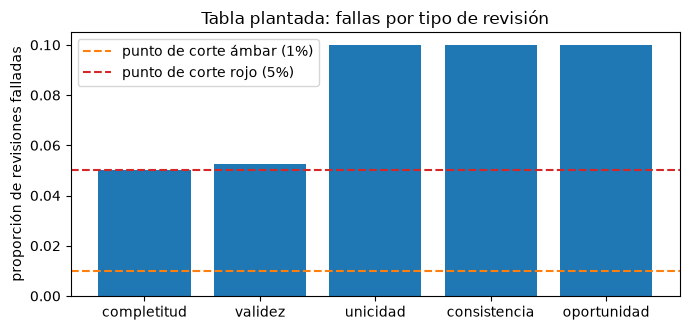

In [11]:
# Proporción de revisiones falladas por tipo, contra los puntos de corte ámbar y rojo de la política
shares = [c.n_failed / c.n_checked for c in counts]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(CHECK_NAMES, shares, color="tab:blue")
ax.axhline(0.01, color="tab:orange", linestyle="--", label="punto de corte ámbar (1%)")
ax.axhline(0.05, color="tab:red", linestyle="--", label="punto de corte rojo (5%)")
ax.set_ylabel("proporción de revisiones falladas")
ax.set_title("Tabla plantada: fallas por tipo de revisión")
ax.legend()
fig.tight_layout()
plt.show()

Las barras son la proporción de revisiones falladas de cada tipo y las dos líneas punteadas son los puntos de corte de
la política. Los cinco tipos quedan en el rojo o sobre él: falta el 0,0500 de las celdas, falla el 0,0526 de las
revisiones de rango y los tres tipos que miran filas fallan en 0,1000. La prueba lee la proporción **mayor**, por eso la
luz es roja con 0,1000, por bien que estén los otros tipos. La tabla se construyó con exactamente un defecto de cada
tipo, así que la figura muestra cómo se lee una luz y no cuán frecuente es cada defecto en una cartera real, donde
suele dominar un solo tipo.

### Paso 7: la prueba versionada sobre el modelo real

La variante del caso C20 corrió las mismas cuatro pruebas sobre un modelo LightGBM con 30.000 tarjetas de Taiwán, una vez con la variable plantada y otra sobre el control limpio. La celda siguiente lista las dos filas `ml.leakage_screen` que escribió la cadena de cálculo, con la versión del motor que las produjo (la cadena de cálculo llama a la misma función que llamó este notebook).

In [12]:
# Las dos filas ml.leakage_screen versionadas: el modelo con la variable plantada y el control limpio
rows = [t for t in variant["tests"] if t["test_id"] == "ml.leakage_screen"]
print("filas:", len(rows), "| horneado con riskvalidation", variant["provenance"]["riskvalidation_version"])
for t in rows:
    print(
        f"{t['model_id']:34s} luz: {LIGHT[t['light']]:6s} pruebas activadas: {int(t['statistic'])} | n {t['n']}"
    )
    for name, s in t["extras"]["screens"].items():
        print(f"    {SCREEN[name]:12s} valor {s['value']:.4f} luz: {LIGHT[s['light']]}")

filas: 2 | horneado con riskvalidation 1.0.1
P4-lightgbm-taiwan-planted-leak    luz: rojo   pruebas activadas: 2 | n 30000
    temporal     valor 9000.0000 luz: rojo
    una variable valor 0.9998 luz: rojo
    traslape     valor 0.0000 luz: verde
    semejanza    valor 0.4932 luz: verde
P4-lightgbm-taiwan                 luz: verde  pruebas activadas: 0 | n 30000
    temporal     valor 0.0000 luz: verde
    una variable valor 0.6833 luz: verde
    traslape     valor 0.0000 luz: verde
    semejanza    valor 0.4986 luz: verde


### Paso 8: la evidencia, dibujada

La última celda dibuja, para las dos muestras del motor, el AUC de cada columna contra la línea de 0,95, y para la variante versionada el AUC del modelo en la muestra de desarrollo contra el momento de decidir. La fuga es invisible en el primer número y evidente en la caída al segundo.

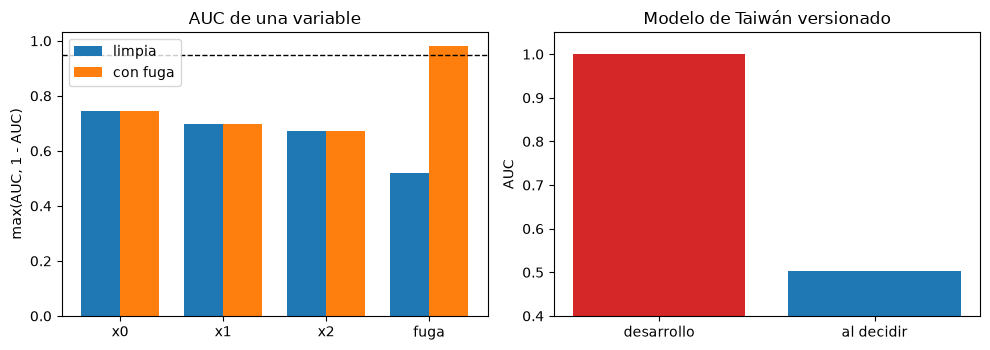

In [13]:
# Izquierda: AUC de cada columna con el corte 0,95; derecha: AUC de desarrollo contra AUC al decidir
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
width = 0.38
for k, (label, (X, y, _)) in enumerate(samples.items()):
    aucs = [float(disc.disc_auc(X[:, j], y).metric) for j in range(X.shape[1])]
    folded = [max(a, 1 - a) for a in aucs]
    left.bar(np.arange(len(folded)) + (k - 0.5) * width, folded, width=width, label=label)
left.axhline(0.95, color="black", linestyle="--", linewidth=1)
left.set_xticks(range(4))
left.set_xticklabels(["x0", "x1", "x2", "fuga"])
left.set_ylabel("max(AUC, 1 - AUC)")
left.set_title("AUC de una variable")
left.legend(loc="upper left")
right.bar(
    ["desarrollo", "al decidir"],
    [perf["development_auc"], perf["decision_time_auc"]],
    color=["tab:red", "tab:blue"],
)
right.set_ylim(0.4, 1.05)
right.set_ylabel("AUC")
right.set_title("Modelo de Taiwán versionado")
fig.tight_layout()
plt.show()

## Resultados

**Respuesta:** No sobre la muestra con fuga, y sí sobre la limpia, y las pruebas dicen cuál es cuál. El AUC de una variable marca 0,9818 en la muestra con fuga contra 0,7454 en la limpia, lo que pone la luz en rojo. En el modelo de Taiwán versionado la variable plantada `future_status_code` sube el AUC a 0,9997 en la muestra de desarrollo y cae a 0,5028 al momento de decidir, mientras la prueba leyó 0,9998 en la variable. La tabla de datos plantada falla 5 de 69 celdas o filas revisadas, con una peor proporción de 0,1000: rojo.

- **Una muestra limpia pasa, y una variable honesta y fuerte no es una fuga.** La muestra limpia no activa ninguna de las cuatro pruebas. Su mejor columna ordena a los incumplidores con un AUC de 0,7454, bien bajo la línea de 0,95, que es como se ve la información crediticia real.
- **La fuga plantada la encuentra la prueba hecha para encontrarla, y solo esa.** En la muestra con fuga el AUC de una variable es 0,9818 (el valor exacto para fuerza 3 es 0,9831; la diferencia es ruido de muestreo) y la luz es roja con una prueba activada. El orden temporal, el traslape y la semejanza siguen en verde, porque esta fuga está en el valor de una variable y no dice nada de fechas, entidades ni poblaciones.
- **La prueba de semejanza tiene alcance limitado.** Sobre la planta de desplazamiento del motor marca 0,5058 sin desplazamiento y 0,6109 con un desplazamiento de 1,5 desviaciones en una cuarta parte de las filas. Ambos quedan bajo el punto de corte de 0,70: la prueba está en verde sobre una población que sí se movió. Es una prueba para diferencias grandes entre la muestra de desarrollo y la fuera de tiempo, y un lector no debe tomar el verde como "las muestras son parecidas".
- **La calidad de datos es un conteo, y decide la mayor proporción.** La tabla plantada falla 5 de las 69 celdas o filas revisadas y su peor proporción es 0,1000 (un identificador repetido, una vista que no coincide y una fecha vieja, 1 de cada 10), así que la luz es roja; la copia reparada no falla ninguna y está en verde. Los puntos de corte (1% y 5%) son convenciones.
- **La variante versionada de C20 coincide.** En el modelo de Taiwán la variable plantada `future_status_code` activa dos pruebas: 9.000 valores de variables fechados después de la observación y un AUC de una variable de 0,9998. El control limpio no activa ninguna (su mejor variable sola da 0,6833). El modelo con la fuga marca un AUC de 0,9997 en la muestra de desarrollo y 0,5028 al momento de decidir, cuando la fuga no está disponible. Las filas se hornearon con riskvalidation 1.0.1, la versión instalada aquí.

Lo que las pruebas no muestran: encuentran las formas de fuga para las que se hicieron. Una fuga repartida en varias variables de aspecto honesto, o una variable legítimamente fechada pero causada por el resultado, pasa las cuatro. Una prueba en verde es la ausencia de estos hallazgos, nunca la prueba de que la muestra es apta. Las fugas plantadas son sintéticas y los puntos de corte son convenciones, no umbrales regulatorios.

## Resumen

- Un validador lee la muestra antes que el modelo: una variable que lleva la respuesta hace halagadora toda cifra de desempeño posterior.
- El motor tiene cuatro pruebas de fuga: el orden temporal y el traslape de entidades son reglas (una violación es una fuga), el AUC de una variable (sobre 0,95) y el AUC de semejanza con ajuste cruzado (sobre 0,70) tienen puntos de corte; `leakage_screen` toma la peor luz de las cuatro y cuenta las que se activaron.
- Cada prueba encuentra una forma de fuga y es ciega a las otras, por eso las cuatro corren juntas y un resultado en verde es una ausencia de hallazgos.
- La calidad de datos son cinco revisiones contadas (completitud, validez, unicidad, consistencia, oportunidad); la luz sigue la mayor proporción de fallas.
- La variante versionada de C20 es la misma lógica en un modelo real: la variable plantada activa dos pruebas, el control limpio ninguna, y el AUC cae de 0,9997 a 0,5028 cuando la fuga ya no está.

**Qué probar después.** El notebook 02 de este tema tensiona un modelo que la muestra ya pasó: ruido en las entradas, desplazamiento y sobreajuste. Después, el tema 14 mide con qué frecuencia pruebas como estas atrapan un defecto plantado y con qué frecuencia se activan sobre un modelo correcto.

## Referencias

- BCE (2019), Instrucciones para informar los resultados de validación de modelos internos: modelos IRB del Pilar I para riesgo de crédito, Anexo 1 (el AUC y su varianza). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- ING (2026), probatus, `sample_similarity`: un modelo de semejanza entre dos conjuntos de datos. https://github.com/ing-bank/probatus
- EBA (2023), Follow-up report on machine learning for IRB models, EBA/REP/2023/28. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2023/1061483/Follow-up%20report%20on%20machine%20learning%20for%20IRB%20models.pdf
- Yeh, I-C. y Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), las tarjetas de Taiwán de las variantes de C20. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients